# 04 · Expression — EMT-TF readout of the axis (unconditional)

The unconditional final notebook (renumbered 04 for the non-branching path).
Score a widened EMT-TF panel — Snail/Zeb/Twist **plus** the FOXC and PRRX
families — **gated on detectable expression** (VIM excluded: it is a
mesenchymal marker, not a transcription factor). Overlay the two factors
demarcating the pseudotime ends as a **categorical** overlay of thresholded
expressers on a grey manifold (not a continuous single-gene colormap).
B-cell lymphoma is non-epithelial, so most classical EMT-TFs are undetectable;
the panel reports which factors clear the detection gate. Deliverable:
`expression.pdf`.

In [ ]:
import os, sys, glob, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

### Load signatures; use the house linear layout

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 22599 | pseudotime range 0.0 -> 8.76


### EMT-TF panel — detection-gated, ranked along pseudotime
Widened panel (Snail/Zeb/Twist + FOXC + PRRX). Keep only factors expressed in
>3% of malignant cells; the earliest- and latest-along-pseudotime survivors
demarcate the axis ends.

In [ ]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
print('panel present in var:', present)
print('panel absent:', [g for g in panel if g not in adata.var_names])
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; expr = x > 0
    rho,p = spearmanr(tn, x)
    rows.append((g, round(expr.mean(),3), round(x[early].mean(),3),
                 round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
print('\ndetection-gated (frac_expr>0.03):', ok.TF.tolist())
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
late_tf  = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print(f'derived pair: {early_tf} (early/root) <-> {late_tf} (late/terminus)')

panel present in var: ['SNAI1', 'SNAI2', 'ZEB1', 'ZEB2', 'FOXC1', 'FOXC2', 'PRRX1']
panel absent: ['TWIST1', 'TWIST2', 'PRRX2']
   TF  frac_expr  mean_early  mean_late  rho_vs_t            end
 ZEB2      0.166       0.130      0.082    -0.035    EARLY(root)
PRRX1      0.000       0.000      0.000    -0.005 LATE(terminus)
SNAI1      0.013       0.011      0.005     0.007    EARLY(root)
FOXC2      0.000       0.000      0.000     0.008 LATE(terminus)
SNAI2      0.004       0.002      0.004     0.030 LATE(terminus)
FOXC1      0.016       0.005      0.006     0.032 LATE(terminus)
 ZEB1      0.107       0.051      0.056     0.064 LATE(terminus)

detection-gated (frac_expr>0.03): ['ZEB2', 'ZEB1']
derived pair: ZEB2 (early/root) <-> ZEB1 (late/terminus)


### EMT-TF expression overlay (deliverable)
Categorical overlay: cells above the upper-quartile-among-expressers threshold
for each of the two factors, coloured on a grey manifold.

overlay thresholds (upper quartile among expressers): {'ZEB2': 0.867, 'ZEB1': 0.703} | cells shown: {'ZEB2': 941, 'ZEB1': 602}
ZEB2: 16.6% expressing; 941 shown (upper quartile), mean pseudotime of shown cells = 0.31 (all cells = 0.45)
ZEB1: 10.7% expressing; 602 shown (upper quartile), mean pseudotime of shown cells = 0.36 (all cells = 0.45)
shown-cell pseudotime separation (ZEB2 vs ZEB1) = 0.06
saved expression.pdf


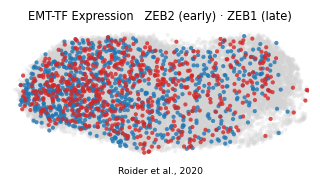

In [ ]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [early_tf, late_tf]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [early_tf, late_tf]})
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {early_tf} (early) · {late_tf} (late)', size=7.5)
ax.text(.5,-.14,'Roider et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
for g in [early_tf, late_tf]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown (upper quartile), '
          f'mean pseudotime of shown cells = {tn[m].mean():.2f} (all cells = {tn.mean():.2f})')
sep = abs(tn[sel[late_tf]].mean() - tn[sel[early_tf]].mean())
print(f'shown-cell pseudotime separation ({early_tf} vs {late_tf}) = {sep:.2f}')
print('saved expression.pdf')